# 0. Setup

In [1]:
import json
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from tqdm.auto import tqdm
import warnings
import copy

warnings.filterwarnings("ignore", category=DeprecationWarning)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


# 1. Data

In [2]:
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.0784,), (0.7843,))
])

train_set = torchvision.datasets.MNIST('./data', train=True,  download=True, transform=transform)
test_set = torchvision.datasets.MNIST('./data', train=False, download=True, transform=transform)

BLANK_PIXEL_VALUE = (0.0 - 0.0784) / 0.7843

class BlankDataset(torch.utils.data.Dataset):
    def __init__(self, mnist_dataset, size: int, noise_std: float = 0.05):
        self.mnist = mnist_dataset
        self.size = size
        self.noise_std = noise_std

    def __len__(self):
        return self.size

    def __getitem__(self, _idx):
        canvas = torch.full((1, 32, 32), BLANK_PIXEL_VALUE)

        # 60% between characters, 40% purely empty
        if torch.rand(1).item() < 0.6:
            left_img, _ = self.mnist[torch.randint(len(self.mnist), (1,)).item()]
            right_img, _ = self.mnist[torch.randint(len(self.mnist), (1,)).item()]

            left_crop_width  = torch.randint(4, 12, (1,)).item()
            right_crop_width = torch.randint(4, 12, (1,)).item()

            canvas[:, :, :left_crop_width]       = left_img[:, :, 32 - left_crop_width:]
            canvas[:, :, 32 - right_crop_width:] = right_img[:, :, :right_crop_width]

        if self.noise_std > 0:
            canvas = canvas + torch.randn_like(canvas) * self.noise_std

        return canvas, BLANK_LABEL


blank_train = BlankDataset(train_set, size=6_000,  noise_std=0.05)
blank_test = BlankDataset(test_set,  size=1_000,  noise_std=0.0)

combined_train = torch.utils.data.ConcatDataset([train_set, blank_train])
combined_test = torch.utils.data.ConcatDataset([test_set,  blank_test])

train_loader = torch.utils.data.DataLoader(combined_train, batch_size=1,  shuffle=True)
test_loader = torch.utils.data.DataLoader(combined_test,  batch_size=256, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 351kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.18MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.6MB/s]


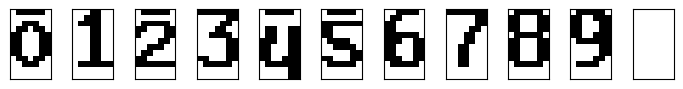

In [3]:
BLANK_LABEL = 10

PROTOTYPES = {
    0: [-1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,+1,+1,+1,-1,-1,
        -1,+1,+1,-1,+1,+1,-1, +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1,
        +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1, -1,+1,+1,-1,+1,+1,-1,
        -1,-1,+1,+1,+1,-1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    1: [-1,-1,-1,+1,+1,-1,-1, -1,-1,+1,+1,+1,-1,-1, -1,+1,+1,+1,+1,-1,-1,
        -1,-1,-1,+1,+1,-1,-1, -1,-1,-1,+1,+1,-1,-1, -1,-1,-1,+1,+1,-1,-1,
        -1,-1,-1,+1,+1,-1,-1, -1,-1,-1,+1,+1,-1,-1, -1,-1,-1,+1,+1,-1,-1,
        -1,+1,+1,+1,+1,+1,+1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    2: [-1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, -1,+1,+1,+1,+1,+1,-1,
        +1,+1,-1,-1,-1,+1,+1, +1,-1,-1,-1,-1,+1,+1, -1,-1,-1,-1,+1,+1,-1,
        -1,-1,+1,+1,+1,-1,-1, -1,+1,+1,-1,-1,-1,-1, +1,+1,-1,-1,-1,-1,-1,
        +1,+1,+1,+1,+1,+1,+1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    3: [+1,+1,+1,+1,+1,+1,+1, -1,-1,-1,-1,-1,+1,+1, -1,-1,-1,-1,+1,+1,-1,
        -1,-1,-1,+1,+1,-1,-1, -1,-1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,+1,+1,
        -1,-1,-1,-1,-1,+1,+1, -1,-1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1,
        -1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    4: [-1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1,
        -1,+1,+1,-1,-1,+1,+1, -1,+1,+1,-1,-1,+1,+1, +1,+1,+1,-1,-1,+1,+1,
        +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,+1,+1,+1,
        -1,+1,+1,+1,+1,+1,+1, -1,-1,-1,-1,-1,+1,+1, -1,-1,-1,-1,-1,+1,+1],
    5: [-1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, +1,+1,+1,+1,+1,+1,+1,
        +1,+1,-1,-1,-1,-1,-1, +1,+1,-1,-1,-1,-1,-1, -1,+1,+1,+1,+1,-1,-1,
        -1,-1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1,
        -1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    6: [-1,-1,+1,+1,+1,+1,-1, -1,+1,+1,-1,-1,-1,-1, +1,+1,-1,-1,-1,-1,-1,
        +1,+1,-1,-1,-1,-1,-1, +1,+1,+1,+1,+1,+1,-1, +1,+1,+1,-1,-1,+1,+1,
        +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1, +1,+1,+1,-1,-1,+1,+1,
        -1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    7: [+1,+1,+1,+1,+1,+1,+1, -1,-1,-1,-1,-1,+1,+1, -1,-1,-1,-1,-1,+1,+1,
        -1,-1,-1,-1,+1,+1,-1, -1,-1,-1,+1,+1,-1,-1, -1,-1,-1,+1,+1,-1,-1,
        -1,-1,+1,+1,-1,-1,-1, -1,-1,+1,+1,-1,-1,-1, -1,-1,+1,+1,-1,-1,-1,
        -1,-1,+1,+1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    8: [-1,+1,+1,+1,+1,+1,-1, +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1,
        +1,+1,-1,-1,-1,+1,+1, -1,+1,+1,+1,+1,+1,-1, +1,+1,-1,-1,-1,+1,+1,
        +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,-1,+1,+1,
        -1,+1,+1,+1,+1,+1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    9: [-1,+1,+1,+1,+1,+1,-1, +1,+1,-1,-1,+1,+1,+1, +1,+1,-1,-1,-1,+1,+1,
        +1,+1,-1,-1,-1,+1,+1, +1,+1,-1,-1,+1,+1,+1, -1,+1,+1,+1,+1,+1,+1,
        -1,-1,-1,-1,-1,+1,+1, -1,-1,-1,-1,-1,+1,+1, -1,-1,-1,-1,+1,+1,-1,
        -1,+1,+1,+1,+1,-1,-1, -1,-1,-1,-1,-1,-1,-1, -1,-1,-1,-1,-1,-1,-1],
    BLANK_LABEL: [-1] * 84,
}

fig, axes = plt.subplots(1, 11, figsize=(7, 1), facecolor="white")
for ax, (_, pix) in zip(axes, PROTOTYPES.items()):
    ax.imshow(np.array(pix).reshape(12, 7) * -1, cmap="gray", vmin=-1, vmax=1)
    ax.set(xticks=[], yticks=[])
plt.tight_layout()
plt.show()

# 2. Model

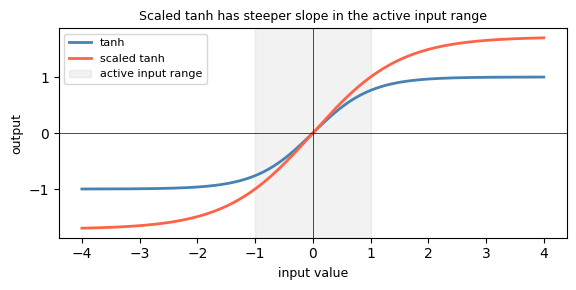

In [4]:
A = 1.7159
S = 2.0 / 3.0

def scaled_tanh(x):
    return A * torch.tanh(S * x)

x = torch.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, torch.tanh(x), color='steelblue', linewidth=2, label='tanh')
ax.plot(x, scaled_tanh(x), color='tomato', linewidth=2, label='scaled tanh')
ax.axvspan(-1, 1, alpha=0.1, color='gray', label='active input range')
ax.axhline(0, color='k', linewidth=0.5)
ax.axvline(0, color='k', linewidth=0.5)
ax.set_xlabel('input value', fontsize=9)
ax.set_ylabel('output', fontsize=9)
ax.set_title('Scaled tanh has steeper slope in the active input range', fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
class SubsamplingLayer(nn.Module):
    def __init__(self, n_maps):
        super().__init__()
        self.pool = nn.AvgPool2d(2, stride=2)
        self.weight = nn.Parameter(torch.ones(1, n_maps, 1, 1))
        self.bias = nn.Parameter(torch.zeros(1, n_maps, 1, 1))

    def forward(self, x):
        return scaled_tanh(self.weight * self.pool(x) + self.bias)

C3_TABLE = [
    [0,1,2], [1,2,3], [2,3,4], [3,4,5], [4,5,0], [5,0,1],
    [0,1,2,3], [1,2,3,4], [2,3,4,5], [3,4,5,0], [4,5,0,1], [5,0,1,2],
    [0,1,3,4], [1,2,4,5], [0,2,3,5],
    [0,1,2,3,4,5]
]
class SparseC3(nn.Module):
    def __init__(self):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv2d(len(c), 1, 5) for c in C3_TABLE])

    def forward(self, x):
        return torch.cat(
            [scaled_tanh(conv(x[:, idx])) for conv, idx in zip(self.convs, C3_TABLE)],
            dim=1
        )
        
class RBFLayer(nn.Module):
    def __init__(self):
        super().__init__()
        W = torch.tensor(list(PROTOTYPES.values()), dtype=torch.float32)
        self.register_buffer('W', W)

    def forward(self, x):
        return ((x.unsqueeze(1) - self.W) ** 2).sum(-1)


class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.C1 = nn.Conv2d(1,   6, 5)
        self.S2 = SubsamplingLayer(6)
        self.C3 = SparseC3()
        self.S4 = SubsamplingLayer(16)
        self.C5 = nn.Conv2d(16, 120, 5)
        self.F6 = nn.Linear(120, 84)
        self.out = RBFLayer()
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                bound = 2.4 / m.weight[0].numel()
                nn.init.uniform_(m.weight, -bound, bound)
                if m.bias is not None:
                    nn.init.uniform_(m.bias, -bound, bound)

    def forward(self, x):
        x = scaled_tanh(self.C1(x))
        x = self.S2(x)
        x = self.C3(x)
        x = self.S4(x)
        x = scaled_tanh(self.C5(x))
        x = scaled_tanh(self.F6(x.flatten(1)))
        return self.out(x)

# 3. Training

In [6]:
class MAPLoss(nn.Module):
    def __init__(self, j=0.1):
        super().__init__()
        self.j = j

    def forward(self, dist, labels):
        B = dist.size(0)
        idx = torch.arange(B, device=dist.device)
        y_c = dist[idx, labels]
        map_term = torch.log(
            torch.exp(torch.tensor(-self.j, device=dist.device)) +
            torch.exp(-dist).sum(dim=1)
        )
        return (y_c + map_term).mean()

Epoch  1/20:   0%|          | 0/66000 [00:00<?, ?it/s]

Epoch  1/20 | loss=7.37 | train_err=6.63% | test_err=1.90%


Epoch  2/20:   0%|          | 0/66000 [00:00<?, ?it/s]

Epoch  2/20 | loss=2.91 | train_err=1.83% | test_err=1.48%
  → lr = 0.0002


Epoch  3/20:   0%|          | 0/66000 [00:00<?, ?it/s]

...

Epoch 18/20 | loss=1.24 | train_err=0.38% | test_err=0.80%


Epoch 19/20:   0%|          | 0/66000 [00:00<?, ?it/s]

Epoch 19/20 | loss=1.24 | train_err=0.38% | test_err=0.81%


Epoch 20/20:   0%|          | 0/66000 [00:00<?, ?it/s]

Epoch 20/20 | loss=1.23 | train_err=0.38% | test_err=0.79%
Best test_err: 0.77%


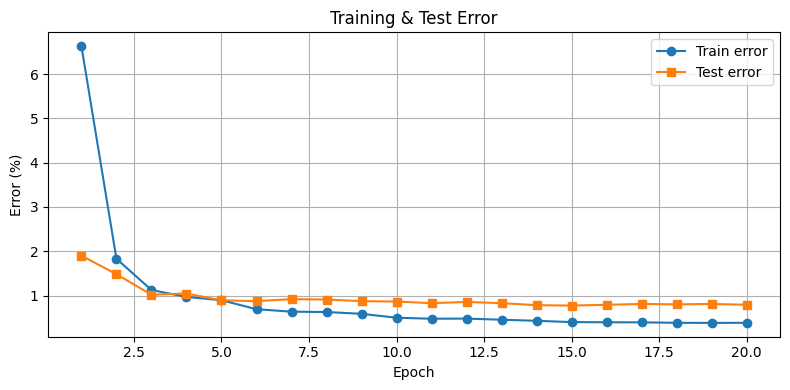

In [7]:
EPOCHS = 20
INITIAL_LR = 5e-4
LR_SCHEDULE = {3: 2e-4, 6: 1e-4, 10: 5e-5, 15:1e-5}

model = LeNet5().to(device)
criterion = MAPLoss(j=0.1)
optimizer = optim.SGD(model.parameters(), lr=INITIAL_LR)
train_errors, test_errors = [], []
CLASS_NAMES = [str(d) for d in range(10)] + ["blank"]
best_err = float('inf')

for epoch in range(1, EPOCHS + 1):
    if epoch in LR_SCHEDULE:
        for g in optimizer.param_groups:
            g['lr'] = LR_SCHEDULE[epoch]
        print(f"  → lr = {LR_SCHEDULE[epoch]}")
        
    model.train()
    run_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch:2d}/{EPOCHS}", leave=False, mininterval=10)
    
    for batch_idx, (imgs, lbls) in enumerate(pbar):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        dist = model(imgs)
        loss = criterion(dist, lbls)
        loss.backward()
        optimizer.step()
        run_loss += loss.item() * imgs.size(0)
        correct  += (dist.argmin(1) == lbls).sum().item()
        total    += imgs.size(0)
        if batch_idx % 50 == 0:
            pbar.set_postfix(
                loss=f"{run_loss/total:.2f}",
                train_err=f"{(1 - correct/total)*100:.2f}%"
            )
    
    model.eval()
    t_ok, t_n = 0, 0
    with torch.no_grad():
        for imgs, lbls in test_loader:
            dist = model(imgs.to(device))
            t_ok += (dist.argmin(1).cpu() == lbls).sum().item()
            t_n += imgs.size(0)
    train_err = 1 - correct / total
    test_err = 1 - t_ok / t_n
    if test_err < best_err:
        best_err = test_err
        best_state = copy.deepcopy(model.state_dict())
    train_errors.append(train_err)
    test_errors.append(test_err)
    print(f"Epoch {epoch:2d}/{EPOCHS} | loss={run_loss/total:.2f} | "
          f"train_err={train_err*100:.2f}% | test_err={test_err*100:.2f}%")

model.load_state_dict(best_state)
print(f"Best test_err: {best_err*100:.2f}%")

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), [e*100 for e in train_errors], marker='o', label='Train error')
plt.plot(range(1, EPOCHS + 1), [e*100 for e in test_errors],  marker='s', label='Test error')
plt.xlabel('Epoch')
plt.ylabel('Error (%)')
plt.title('Training & Test Error')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Inference

In [8]:
activations = {}
def make_hook(name):
    def hook(module, inp, out):
        activations[name] = out.detach()
    return hook

model.C1.register_forward_hook(make_hook('C1_pre'))
model.S2.register_forward_hook(make_hook('S2'))
model.C3.register_forward_hook(make_hook('C3'))
model.S4.register_forward_hook(make_hook('S4'))
model.C5.register_forward_hook(make_hook('C5_pre'))
model.F6.register_forward_hook(make_hook('F6_pre'))
model.out.register_forward_hook(make_hook('RBF'))

img_raw, true_label = next(iter(torch.utils.data.DataLoader(test_set, batch_size=1, shuffle=True)))
img_raw = img_raw.to(device)

model.eval()
with torch.no_grad():
    dist = model(img_raw)
    act_c1 = scaled_tanh(activations['C1_pre']).cpu().squeeze()
    act_s2 = activations['S2'].cpu().squeeze()
    act_c3 = activations['C3'].cpu().squeeze()
    act_s4 = activations['S4'].cpu().squeeze()
    act_c5 = scaled_tanh(activations['C5_pre']).cpu().view(-1)
    act_f6 = scaled_tanh(activations['F6_pre']).cpu().squeeze()
    rbf_dist = activations['RBF'].cpu().squeeze()
    prediction = dist.argmin(1).item()

print(f"True: {true_label.item()}  |  Predicted: {prediction}")

True: 8  |  Predicted: 8


# 5. Visualisation

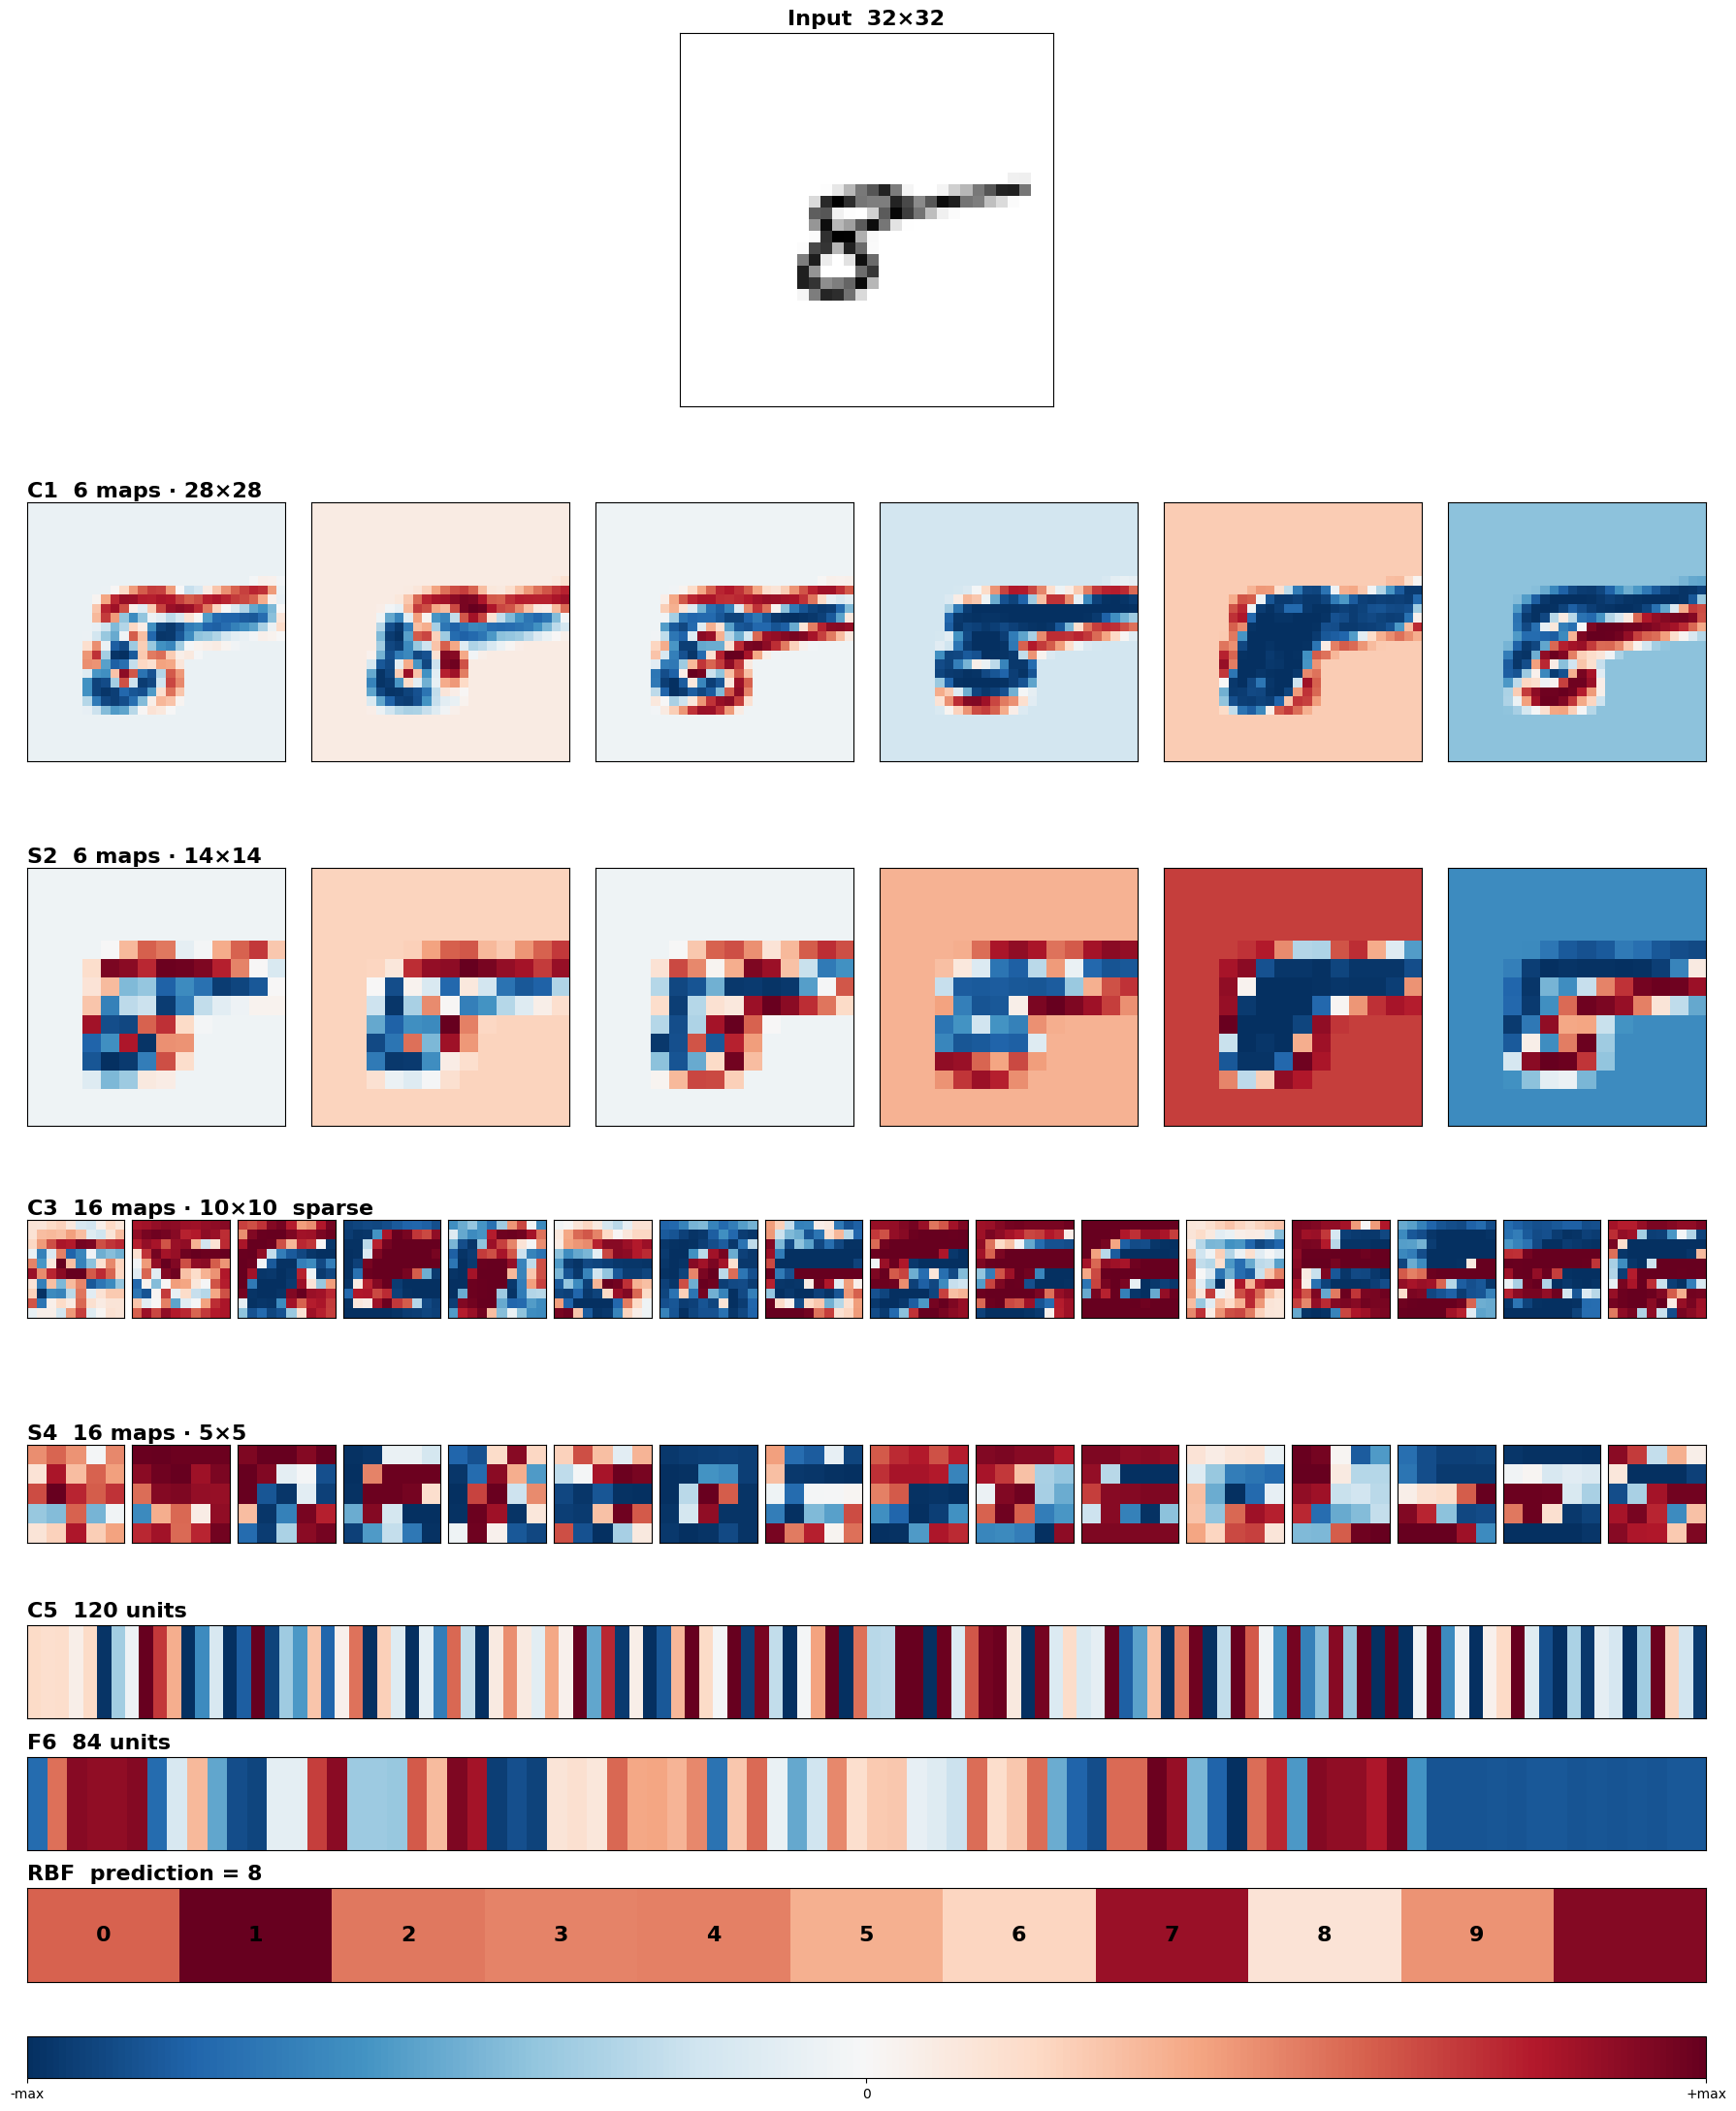

In [9]:
FONTSIZE=16

def plot_input_row(fig, subplot_spec, img, title):
    ax = fig.add_subplot(subplot_spec)
    ax.imshow(img.cpu().squeeze(), cmap='Greys')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=FONTSIZE, weight='bold')

def plot_map(ax, data):
    limit = max(abs(data.min()), abs(data.max())) + 1e-6
    ax.imshow(data, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xticks([]); ax.set_yticks([])

def plot_feature_maps(fig, subplot_spec, activation, title):
    n = activation.shape[0]
    wspace = 0.08 if n > 6 else 0.1
    for i, cell in enumerate(gridspec.GridSpecFromSubplotSpec(1, n, subplot_spec=subplot_spec, wspace=wspace)):
        ax = fig.add_subplot(cell)
        plot_map(ax, activation[i])
        if i == 0:
            ax.set_title(title, loc='left', fontsize=FONTSIZE, weight='bold', pad=4)

def plot_stripe_row(fig, subplot_spec, vector, title):
    ax = fig.add_subplot(subplot_spec)
    limit = max(abs(vector.min()), abs(vector.max())) + 1e-6
    ax.imshow(vector.unsqueeze(0), cmap='RdBu_r', aspect='auto', vmin=-limit, vmax=limit)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=FONTSIZE, weight='bold', loc='left')

def plot_rbf_row(fig, subplot_spec, rbf_dist, title):
    ax  = fig.add_subplot(subplot_spec)
    inv = rbf_dist
    lim = max(abs(inv.min()), abs(inv.max())) + 1e-6
    ax.imshow(inv.unsqueeze(0), cmap='RdBu_r', aspect='auto', vmin=-lim, vmax=lim)
    ax.set_xticks([]); ax.set_yticks([])
    for d in range(10):
        ax.text(d, 0, str(d), ha='center', va='center', fontsize=FONTSIZE, fontweight='bold')
    ax.set_title(title, fontsize=FONTSIZE, weight='bold', loc='left')

def plot_colorbar(fig, subplot_spec):
    ax = fig.add_subplot(subplot_spec)
    ax.set_aspect(0.05)
    cb = mpl.colorbar.ColorbarBase(ax, cmap=plt.get_cmap('RdBu_r'),
                                   norm=mpl.colors.Normalize(vmin=-1, vmax=1),
                                   orientation='horizontal')
    cb.set_ticks([-1, 0, 1])
    cb.set_ticklabels(['-max', '0', '+max'])


fig = plt.figure(figsize=(18, 22), facecolor='white')

gs = gridspec.GridSpec(9, 1, height_ratios=[2, 2, 1.5, 1, 1, 0.5, 0.5, 0.5, 0.4], hspace=0.75)

plot_input_row(fig, gs[0], img_raw, "Input  32×32")
plot_feature_maps(fig, gs[1], act_c1, "C1  6 maps · 28×28")
plot_feature_maps(fig, gs[2], act_s2, "S2  6 maps · 14×14")
plot_feature_maps(fig, gs[3], act_c3, "C3  16 maps · 10×10  sparse")
plot_feature_maps(fig, gs[4], act_s4, "S4  16 maps · 5×5")
plot_stripe_row(fig, gs[5], act_c5, "C5  120 units")
plot_stripe_row(fig, gs[6], act_f6, "F6  84 units")
plot_rbf_row(fig, gs[7], rbf_dist, f"RBF  prediction = {prediction}")
plot_colorbar(fig, gs[8])

gs.tight_layout(fig)
plt.show()

# 6. Export

In [10]:
class LeNet5_Export_SDNN(nn.Module):
    OUTPUT_NAMES = [
        'c1_raw', 'c1_activated',
        's2_raw', 's2_activated',
        'c3_raw', 'c3_activated',
        's4_raw', 's4_activated',
        'c5_raw', 'c5_activated',
        'f6_raw', 'f6_activated',
        'output_distances',
    ]

    def __init__(self, original_model):
        super().__init__()
        self.C1 = original_model.C1
        self.S2 = original_model.S2
        self.C3 = original_model.C3
        self.S4 = original_model.S4
        self.C5 = original_model.C5
        self.rbf = original_model.out
        f6 = original_model.F6
        self.register_buffer('f6_weight', f6.weight.data.view(f6.out_features, f6.in_features, 1, 1))
        self.register_buffer('f6_bias', f6.bias.data)

    def forward(self, x):
        c1_raw, c1_activated = self.C1(x), scaled_tanh(self.C1(x))
        c1_raw = self.C1(x)
        c1_activated = scaled_tanh(c1_raw)

        s2_raw = self.S2.pool(c1_activated) * self.S2.weight + self.S2.bias
        s2_activated = scaled_tanh(s2_raw)

        c3_raw = torch.cat([conv(s2_activated[:, idx])
                                  for conv, idx in zip(self.C3.convs, C3_TABLE)], dim=1)
        c3_activated = scaled_tanh(c3_raw)

        s4_raw = self.S4.pool(c3_activated) * self.S4.weight + self.S4.bias
        s4_activated = scaled_tanh(s4_raw)

        c5_raw = self.C5(s4_activated)
        c5_activated = scaled_tanh(c5_raw)

        f6_raw = F.conv2d(c5_activated, self.f6_weight, self.f6_bias)
        f6_activated = scaled_tanh(f6_raw)

        B, C, _, N = f6_activated.shape
        f6_flat = f6_activated.squeeze(2).permute(0, 2, 1).reshape(B * N, C)
        output_distances = (self.rbf(f6_flat)
                            .reshape(B, N, -1)
                            .permute(0, 2, 1))

        return (
            c1_raw, c1_activated,
            s2_raw, s2_activated,
            c3_raw, c3_activated,
            s4_raw, s4_activated,
            c5_raw, c5_activated,
            f6_raw, f6_activated,
            output_distances,
        )

    def export(self, path: str, device):
        self.eval()
        dynamic_axes = {n: {0: 'batch', 3: 'width'} for n in ['input', *self.OUTPUT_NAMES]}
        dynamic_axes['output_distances'] = {0: 'batch', 2: 'width'}
        torch.onnx.export(
            self,
            torch.randn(1, 1, 32, 32, device=device),
            path,
            input_names=['input'],
            output_names=self.OUTPUT_NAMES,
            dynamic_axes=dynamic_axes,
            opset_version=13,
        )
        print(f"Exported ONNX model → {path}")


LeNet5_Export_SDNN(model).export("lenet5_rbf.onnx", device)

Exported ONNX model → lenet5_rbf.onnx


In [11]:
PRECISION = 3

def _to_rounded_list(data):
    if isinstance(data, dict):
        return {k: _to_rounded_list(v) for k, v in data.items()}
    if isinstance(data, list):
        return [_to_rounded_list(x) for x in data]
    return round(float(data), PRECISION)
    
def _save(name, data):
    path = f"{name}.json"
    with open(path, 'w') as f:
        json.dump(_to_rounded_list(data), f, indent=2)
    print(f"Exported {name} weights → {path}")

def _conv_data(layer):
    return {'weights': layer.weight.detach().cpu().numpy().tolist(),
            'bias':    layer.bias.detach().cpu().numpy().tolist()}

def export_conv(name, layer):
    _save(name, _conv_data(layer))

def export_sparse_conv(name, layer):
    _save(name, {
        'connection_table': C3_TABLE,
        'convolutions': [
            {'output_channel': i, 'input_channels': connections, **_conv_data(conv)}
            for i, (conv, connections) in enumerate(zip(layer.convs, C3_TABLE))
        ],
    })
    
def export_subsampling(name, layer):
    _save(name, {
        'scale': layer.weight.detach().cpu().numpy().flatten().tolist(),
        'bias':  layer.bias.detach().cpu().numpy().flatten().tolist(),
    })

def export_rbf_patterns(name, layer):
    path = f"{name}.json"
    data = [_to_rounded_list(row.tolist()) for row in layer.W.cpu().numpy()]
    with open(path, 'w') as f:
        json.dump(data, f)
    print(f"Exported {name} → {path}")


export_conv('C1', model.C1)
export_subsampling('S2', model.S2)
export_sparse_conv('C3', model.C3)
export_subsampling('S4', model.S4)
export_conv('C5', model.C5)
export_conv ('F6', model.F6)
export_rbf_patterns('rbf_patterns', model.out)

Exported C1 weights → C1.json
Exported S2 weights → S2.json
Exported C3 weights → C3.json
Exported S4 weights → S4.json
Exported C5 weights → C5.json
Exported F6 weights → F6.json
Exported rbf_patterns → rbf_patterns.json
